<div style="border:solid green 2px; padding: 20px">
    
<b>Андрей, привет!</b> Мы рады тебя видеть на территории код-ревьюеров 😎. Ты проделал большую работу над проектом, но давай познакомимся и сделаем его еще лучше! У нас тут своя атмосфера и несколько правил:


1. Меня зовут Александр Матвеевский. Я работаю код-ревьюером, моя основная цель — не указать на совершенные тобою ошибки, а поделиться своим опытом и помочь тебе стать дата-специалистом.
2. Общаемся на ты.
3. Если хочешь написать, спросить - не нужно стесняться. Только выбери свой цвет для комментария.  
4. Это учебный проект, тут можно не бояться сделать ошибку.  
5. У нас с тобой 6 попыток для сдачи проекта.  
6. Let's Go!

---

Я буду красить комментарии цветом, пожалуйста, не удаляй их:

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

Такой комментарий нужно исправить обязательно, он критически влияет на удачное выполнение проекта.
</div>
    
---

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__


Такой комментарий является рекомендацией или советом. Можешь использовать их на своё усмотрение.
</div>

---

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Такой комментарий  говорит о том, что было сделано что-то качественное и правильное =)
</div>
    
---
    
Предлагаю работать над проектом в диалоге: если ты что-то меняешь в проекте или отвечаешь на мои комментарии — пиши об этом. Мне будет легче отследить изменения, если ты выделишь свои комментарии:   
    
<div class="alert alert-info"> <b>Комментарии студента:</b> Например, вот так.</div>
    
Всё это поможет выполнить повторную проверку твоего проекта оперативнее. Если будут какие-нибудь вопросы по моим комментариям, пиши, будем разбираться вместе :)    
    
---

#### Анализ лояльности пользователей Яндекс Афиши
#### Цель и задачи
Цель: понять, какие пользователи с большей вероятностью возвращаются на платформу и делают заказы повторно.
Это позволит:
Быстро выявлять перспективных клиентов и предлагать им персонализированные условия.
Точно настраивать рекламу на аудитории с высокой вероятностью возврата.
Оптимизировать маркетинговые бюджеты.
Повысить общий уровень удержания клиентов.

#### Задачи:

- Загрузить данные и познакомиться с их содержимым.
- Провести предобработку данных.
- Провести исследовательский анализ данных:
- изучить данные более детально;
- изучить взаимосвязь данных в столбце Сhurn с другими данными.
- Сформулировать выводы по проведённому анализу.

#### Для анализа была сформирована витрина данных на основе которой будет проводиться исследование:

- user_id — уникальный идентификатор пользователя, совершившего заказ;
- device_type_canonical — тип устройства, с которого был оформлен заказ ( mobile — мобильные устройства, desktop — стационарные);
- order_id — уникальный идентификатор заказа;
- order_dt — дата создания заказа (используйте данные created_dt_msk );
- order_ts — дата и время создания заказа (используйте данные created_ts_msk );
- currency_code — валюта оплаты;
- revenue — выручка от заказа;
- tickets_count — количество купленных билетов;
- days_since_prev — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- event_id — уникальный идентификатор мероприятия;
- service_name — название билетного оператора;
- event_type_main — основной тип мероприятия (театральная постановка, концерт и так далее);
- region_name — название региона, в котором прошло мероприятие;
- city_name — название города, в котором прошло мероприятие.

#### Структура проекта
- Загрузка данных.
- Предобработка данных.
- Создание профиля пользователя.
- Исследовательский анализ данных
- Итоговые выводы.
- Финализация проекта и публикация в Git.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
 
Хорошее вступление!
    
В нём есть всё, что необходимо, чтобы понять суть проекта с первых строк отчёта: отлично, что сформулирована цель проекта, описаны шаги выполнения проекта и входные данные.

In [1]:
!pip install sqlalchemy

In [2]:
!pip install psycopg2

In [3]:
!pip install phik

In [4]:
import pandas as pd

from sqlalchemy import create_engine

import matplotlib.pyplot as plt

import seaborn as sns

from phik import phik_matrix

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Хорошо, что все импорты собраны в первой ячейке кода, это соответствует оформлению кода <a href='https://pyplanet.ru/article/pep-0008.html'>PEP 8</a> и помогает понять, какое окружение используется в проекте.

In [5]:
db_config = {'user': 'praktikum_student', # имя пользователя
             'pwd': 'Sdf4$2;d-d30pp', # пароль
             'host': 'rc1b-wcoijxj3yxfsf3fs.mdb.yandexcloud.net',
             'port': 6432, # порт подключения
             'db': 'data-analyst-afisha' # название базы данных
             }

In [6]:
connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

In [7]:
engine = create_engine(connection_string)

In [8]:
query = '''
WITH set_config_precode AS (
  SELECT set_config('synchronize_seqscans', 'off', true)
)
SELECT 
  user_id,
  device_type_canonical,
  order_id,
  created_dt_msk order_dt,
  created_ts_msk order_ts,
  currency_code,
  revenue,
  tickets_count,
  (created_dt_msk::date - LAG(created_dt_msk::date)OVER(PARTITION BY user_id ORDER BY created_dt_msk))days_since_prev,
  e.event_id,
  event_name_code AS event_name,
  event_type_main,
  service_name,
  region_name,
  city_name
FROM afisha.purchases p
JOIN afisha.events e ON p.event_id = e.event_id
JOIN afisha.city c ON e.city_id = c.city_id 
JOIN afisha.regions r ON c.region_id = r.region_id
WHERE e.event_type_main != 'фильм' AND device_type_canonical IN ('mobile','desktop')
ORDER BY user_id ASC
'''

In [9]:
#df = pd.read_sql_query(query, con=engine)

In [10]:
#df.head()

In [11]:
#df.info()

In [12]:
df = pd.read_csv('afisha_data.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   user_id                290611 non-null  object 
 1   device_type_canonical  290611 non-null  object 
 2   order_id               290611 non-null  int64  
 3   order_dt               290611 non-null  object 
 4   order_ts               290611 non-null  object 
 5   currency_code          290611 non-null  object 
 6   revenue                290611 non-null  float64
 7   tickets_count          290611 non-null  int64  
 8   days_since_prev        268678 non-null  float64
 9   event_id               290611 non-null  int64  
 10  event_name             290611 non-null  object 
 11  event_type_main        290611 non-null  object 
 12  service_name           290611 non-null  object 
 13  region_name            290611 non-null  object 
 14  city_name              290611 non-nu

In [13]:
print("0. Исходное число пользователей:", df['user_id'].nunique())

0. Исходное число пользователей: 21933


In [14]:
df['order_dt'] = pd.to_datetime(df['order_dt'])
df['order_ts'] = pd.to_datetime(df['order_ts'])
df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк


<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
    
* Выгрузка данных проведена корректно! Была выполнена необходимая фильтрация данных, выгружены только необходимые для анализа данные. Отлично, что сразу подсчитываешь время между заказами для каждого пользователя.
    


</div>

### Шаг 2. Предобработка данных

#### Задача 2.1. 
Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведите выручку к единой валюте — российскому рублю.
Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — final_tickets_tenge_df.csv. Его можно скачать по ссылке. Значения в рублях представлено для 100 тенге.
Результаты преобразования сохраните в новый столбец revenue_rub.

In [15]:
df_kzt = pd.read_csv('final_tickets_tenge_df.csv')
df_kzt = df_kzt[['data','curs']]
df_kzt.rename(columns={'curs': 'curs_kzt'}, inplace=True)
df_kzt['data'] = pd.to_datetime(df_kzt['data'])
df = df.merge(df_kzt, left_on='order_dt', right_on='data', how='inner')
df.drop('data', axis=1, inplace=True)
df['revenue_rub'] = df['revenue'].where(df['currency_code'] == 'rub', df['revenue'] * df['curs_kzt'] / 100)

In [16]:
print(df[df['currency_code'] == 'kzt'][['revenue','revenue_rub']])

         revenue  revenue_rub
70        518.10    98.503762
89        347.18    65.731589
96        328.77    61.148261
277     22021.55  4380.702898
460      7397.66  1478.296591
...          ...          ...
290484   4735.52   865.359454
290485   4735.52   872.363288
290486   1849.41   343.072953
290488   3698.83   687.209325
290489   3698.83   687.209325

[5069 rows x 2 columns]


In [17]:
print("1. После merge с курсами:", df['user_id'].nunique())

1. После merge с курсами: 21933


<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__


* Существует довольно удобный метод [where](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.where.html). Мы можем применить его к столбцу и указать условие, которое будем проверять, а также альтернативный вариант значения. Если условие выполняется, то берется значение из столбца, если нет - альтернативное значение. Тогда расчет выручки в рублях будет выглядеть следующим образом:
    
    ```python
df['revenue_rub'] = df['revenue'].where(df['currency_code'] == 'rub', df['revenue'] * df['curs'] / 100)
    
    ```
    
Сейчас, если честно не до конца понимаю, как работает твой цикл
    
* было бы лучше вывести только несколько строк и необходимые для проверки столбцы.
    



<div class="alert alert-info"> <b>Комментарии студента:</b> Метод where - применил. Вывел необходимые строки. Спасибо.</div>

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

Супер, старайся, пожалуйста, придерживаться этой стратегии в дальнейших проектах =)
</div>

In [18]:
df.drop(columns=['curs_kzt'], inplace=True)
print(df.info())
display(df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,revenue_rub
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск,1521.94
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск,289.45
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск,1258.57
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск,8.49
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк,1390.41
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
290606,fffcd3dde79eb2c,mobile,368591,2024-10-27,2024-10-27 17:54:52,rub,965.57,4,0.0,33189,e3dcdb45-9eaa-4ce4-9b85-1562e548172e,другое,Весь в билетах,Каменевский регион,Глиногорск,965.57
290607,fffcd3dde79eb2c,mobile,368562,2024-10-27,2024-10-27 17:53:53,rub,1448.36,6,0.0,33189,e3dcdb45-9eaa-4ce4-9b85-1562e548172e,другое,Весь в билетах,Каменевский регион,Глиногорск,1448.36
290608,fffcd3dde79eb2c,desktop,8473772,2024-10-30,2024-10-30 13:37:43,rub,178.95,2,3.0,205231,74883818-57a6-494a-b162-bb0260877cbf,театр,Прачечная,Каменевский регион,Глиногорск,178.95
290609,fffeeb3c120cf0b,desktop,5526067,2024-09-24,2024-09-24 10:07:42,rub,661.53,2,NaN,454526,6f4c6a50-0106-407b-8f54-332c740b01da,стендап,Билеты без проблем,Широковская область,Ягодиновка,661.53


order_id to int32
currency_code to str
revenue to float32
tickets_count to int8
days_since_prev to int16
event_id to int32

Скорее всего event_name имеет некорректное название

In [19]:
df['order_id'] = df['order_id'].astype('int32')
df['currency_code'] = df['currency_code'].astype('string')
df['revenue'] = df['revenue'].astype('float32')
df['tickets_count'] = df['tickets_count'].astype('int8')
df['event_id'] = df['event_id'].astype('int32')
df['revenue_rub'] = df['revenue_rub'].astype('float32')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int32         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  string        
 6   revenue                290611 non-null  float32       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int32         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

##### Выводы
Что сделано:
Выручка в тенге пересчитана в рубли по курсу на дату заказа, для рублёвых заказов значения оставлены без изменений.

Результат:
Создан столбец revenue_rub с единой валютой. Это позволило корректно сравнивать финансовые показатели всех заказов независимо от валюты оплаты.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Ты молодец, что подумал про оптимизацию памяти, это полезная штука, особенно если работаешь с большими датасетами (можем получить смещение данных) 

#### Задача 2.2.
Проверьте данные на пропущенные значения. 
- Если выгрузка из SQL была успешной, то пропуски должны быть только в столбце days_since_prev. + 
- Преобразуйте типы данных в некоторых столбцах, если это необходимо. Обратите внимание на данные с датой и временем, а также на числовые данные, размерность которых можно сократить. +
- Изучите значения в ключевых столбцах. Обработайте ошибки, если обнаружите их.
- Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо. +
- Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха. Важные показатели в рамках поставленной задачи — это выручка с заказа ( revenue_rub ) и количество билетов в заказе ( tickets_count ), поэтому в первую очередь проверьте данные в этих столбцах. Если обнаружите выбросы в поле revenue_rub, то отфильтруйте значения по 99 перцентилю.
После предобработки проверьте, были ли отфильтрованы данные. Если были, то оцените, в каком объёме. Сформулируйте промежуточный вывод, зафиксировав основные действия и описания новых столбцов.

In [20]:
#- Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо.
print(f"для столбца device_type_canonical следующие уникальные значения: {df['device_type_canonical'].unique()}")
print(f"для столбца currency_code следующие уникальные значения: {df['currency_code'].unique()}")
print(f"для столбца tickets_count следующие уникальные значения: {df['tickets_count'].unique()}")
print(f"для столбца service_name следующие уникальные значения: {df['service_name'].unique()}")
print(f"для столбца event_type_main следующие уникальные значения: {df['event_type_main'].unique()}")
#print(f"для столбца region_name следующие уникальные значения: {df['region_name'].unique()}")
#print(f"для столбца city_name следующие уникальные значения: {df['city_name'].unique()}")

для столбца device_type_canonical следующие уникальные значения: ['mobile' 'desktop']
для столбца currency_code следующие уникальные значения: <StringArray>
['rub', 'kzt']
Length: 2, dtype: string
для столбца tickets_count следующие уникальные значения: [ 4  2  3  1  5  6 10  9  7 15 13 11  8 14 12 47 27 17 19 57 30 37]
для столбца service_name следующие уникальные значения: ['Край билетов' 'Мой билет' 'За билетом!' 'Лови билет!'
 'Билеты без проблем' 'Облачко' 'Лучшие билеты' 'Прачечная' 'Быстробилет'
 'Дом культуры' 'Весь в билетах' 'Билеты в руки' 'Тебе билет!'
 'Show_ticket' 'Городской дом культуры' 'Яблоко' 'Билет по телефону'
 'Выступления.ру' 'Росбилет' 'Шоу начинается!' 'Мир касс' 'Восьмёрка'
 'Телебилет' 'Crazy ticket!' 'Реестр' 'Быстрый кассир' 'КарандашРУ'
 'Радио ticket' 'Дырокол' 'Вперёд!' 'Кино билет' 'Цвет и билет' 'Зе Бест!'
 'Тех билет' 'Лимоны' 'Билеты в интернете']
для столбца event_type_main следующие уникальные значения: ['театр' 'выставки' 'другое' 'стендап' 'конц

In [21]:
for column in ['device_type_canonical', 'region_name', 'service_name', 'event_type_main']:
    print(f"\nColumn: {column}")
    print("Unique values:", df[column].unique())
    print("Missing values count:", df[column].isna().sum())
    print("Value counts:")
    print(df[column].value_counts(dropna=False), "\n")


Column: device_type_canonical
Unique values: ['mobile' 'desktop']
Missing values count: 0
Value counts:
device_type_canonical
mobile     232490
desktop     58121
Name: count, dtype: int64 


Column: region_name
Unique values: ['Каменевский регион' 'Североярская область' 'Озернинский край'
 'Лугоградская область' 'Поленовский край' 'Широковская область'
 'Медовская область' 'Златопольский округ' 'Малиновоярский округ'
 'Яблоневская область' 'Ветренский регион' 'Боровлянский край'
 'Крутоводская область' 'Ягодиновская область' 'Серебряноярский округ'
 'Лесодальний край' 'Верхоречная область' 'Горицветская область'
 'Речиновская область' 'Травиницкий округ' 'Сосновская область'
 'Серебринская область' 'Травяная область' 'Каменноярский край'
 'Солнечноземская область' 'Светополянский округ' 'Заречная область'
 'Ручейковский край' 'Глиногорская область' 'Тепляковская область'
 'Каменноозёрный край' 'Солнечнореченская область' 'Зоринский регион'
 'Берёзовская область' 'Лесостепной край' 'Ма

In [22]:
dups_order = df.duplicated(subset=['order_id']).sum()
print(f"Явных дубликатов по order_id: {dups_order}")
df = df.drop_duplicates(subset=['order_id'], keep='first')

# Неявные дубликаты (одинаковые: пользователь, событие, дата, сумма, билеты)
cols = ['user_id', 'event_id', 'order_dt', 'revenue', 'tickets_count']
dups_implicit = df.duplicated(subset=cols, keep=False).sum()
print(f"Неявных дубликатов (по признакам): {dups_implicit}")

# Оставляем успешную транзакцию
df = df.sort_values('order_ts', ascending=False)
df = df.drop_duplicates(subset=cols, keep='first')
df = df.sort_index()

full_dups = df.duplicated(keep=False).sum()
print(f"Полных дубликатов строк: {full_dups}")
df = df.drop_duplicates(keep='first')

print(f"Итоговый размер датафрейма после удаления дубликатов: {len(df)}")

Явных дубликатов по order_id: 0
Неявных дубликатов (по признакам): 86455
Полных дубликатов строк: 0
Итоговый размер датафрейма после удаления дубликатов: 237334


<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__


Тут я бы рекомендовал более тщательнее следить за чистотой данных, проверить категориальные признаки на предмет аномалий и сследить за распределением данных по признакам. Так можно сразу отловить категории с небольшим количеством данных
    
        # Анализ категориальных значений
        for column in ['columnname', 'columnname', 'columnname', 'columnname']:
        print(f"\nColumn: {column}")
        print("Unique values:", df[column].unique())
        print("Missing values count:", df[column].isna().sum())
        print("Value counts:")
        print(df[column].value_counts(dropna=False), "\n")    

<div class="alert alert-info"> <b>Комментарии студента:</b> Перебор использовал в 21 строке. Спасибо.</div>

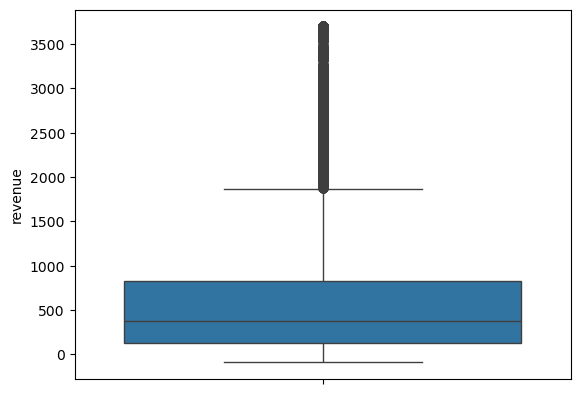

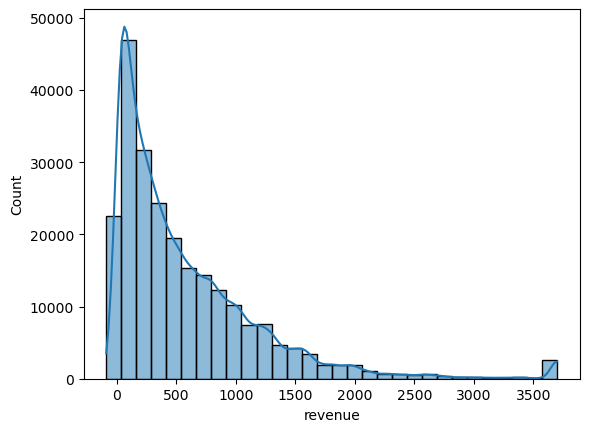

count    237334.000000
mean        576.859009
std         629.012268
min         -90.760002
25%         127.692501
50%         376.100006
75%         824.604996
max        3698.830078
Name: revenue, dtype: float64

In [23]:
for column in ['revenue', 'revenue_rub', 'days_since_prev', 'tickets_count']:
    q = df[column].quantile(0.99)
    df[column] = df[column].clip(upper=q)
sns.boxplot(data = df['revenue'])
plt.show()
sns.histplot(data = df, x= 'revenue',bins = 30, kde = True)
plt.show()
df['revenue'].describe()

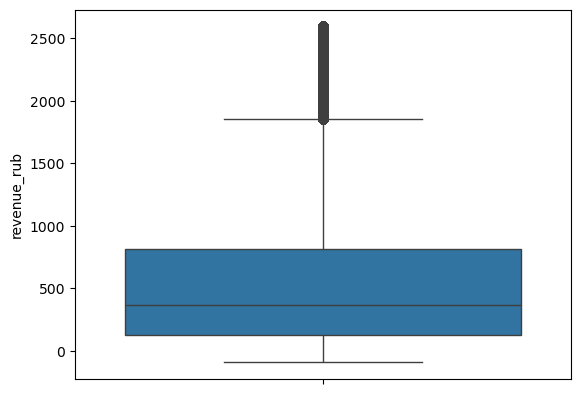

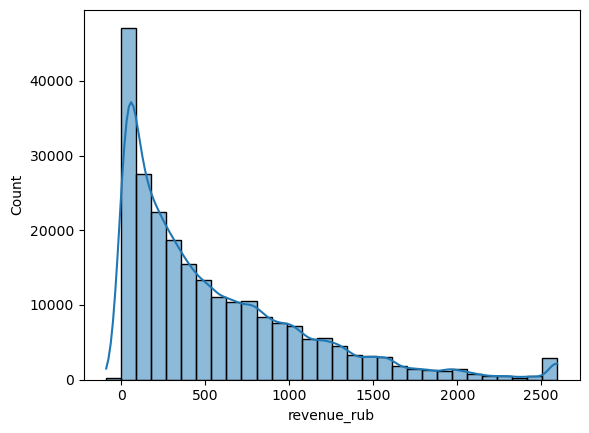

count    237334.000000
mean        548.735901
std         545.477844
min         -90.760002
25%         124.349997
50%         370.494995
75%         815.277527
max        2594.439941
Name: revenue_rub, dtype: float64

In [24]:
sns.boxplot(data = df['revenue_rub'])
plt.show()
sns.histplot(data = df, x= 'revenue_rub',bins = 30, kde = True)
plt.show()
df['revenue_rub'].describe()

In [25]:
neg_count = (df['revenue_rub'] < 0).sum()
print(f"Осталось строк после удаления строй с отрицательной выручкой: {len(df)}")
print(f"Количество строк с отрицательной выручкой: {neg_count}")
df = df[df['revenue_rub'] >= 0]

df = df[df['revenue'] >= 0]

df = df[df['revenue_rub'] >= 0]
print(f"Осталось строк после удаления строк с отрицательной выручкой: {len(df)}")

Осталось строк после удаления строй с отрицательной выручкой: 237334
Количество строк с отрицательной выручкой: 325
Осталось строк после удаления строк с отрицательной выручкой: 237009


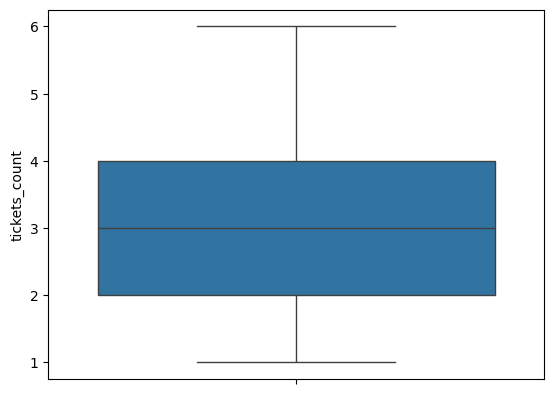

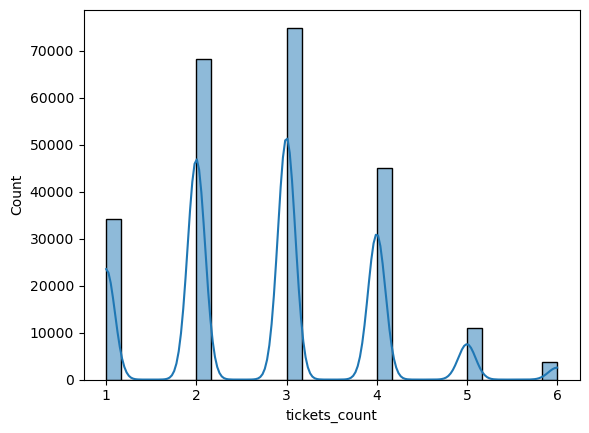

count    237009.000000
mean          2.753030
std           1.148415
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max           6.000000
Name: tickets_count, dtype: float64

In [26]:
sns.boxplot(data = df['tickets_count'])
plt.show()
sns.histplot(data = df, x= 'tickets_count',bins = 30, kde = True)
plt.show()
df['tickets_count'].describe()

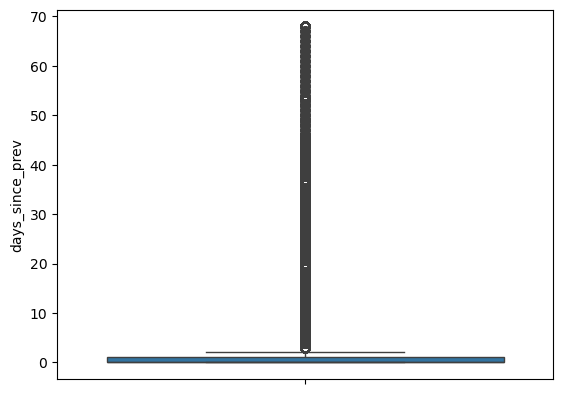

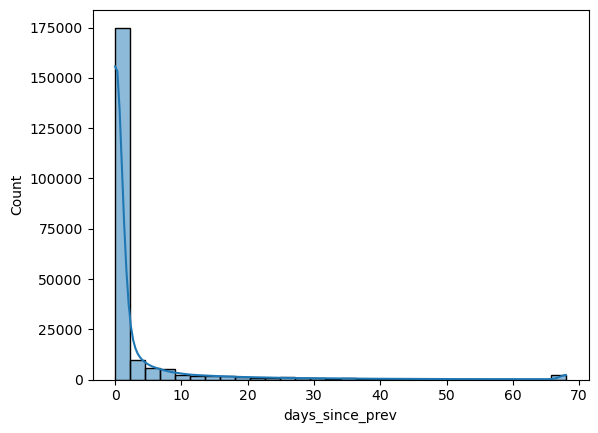

count    216437.000000
mean          3.503948
std          10.384823
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          68.000000
Name: days_since_prev, dtype: float64

In [27]:
sns.boxplot(data = df['days_since_prev'])
plt.show()
sns.histplot(data = df, x= 'days_since_prev',bins = 30, kde = True)
plt.show()
df['days_since_prev'].describe()

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 237009 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                237009 non-null  object        
 1   device_type_canonical  237009 non-null  object        
 2   order_id               237009 non-null  int32         
 3   order_dt               237009 non-null  datetime64[ns]
 4   order_ts               237009 non-null  datetime64[ns]
 5   currency_code          237009 non-null  string        
 6   revenue                237009 non-null  float32       
 7   tickets_count          237009 non-null  int8          
 8   days_since_prev        216437 non-null  float64       
 9   event_id               237009 non-null  int32         
 10  event_name             237009 non-null  object        
 11  event_type_main        237009 non-null  object        
 12  service_name           237009 non-null  object   

In [29]:
print("2. После фильтрации выбросов:", df['user_id'].nunique())

2. После фильтрации выбросов: 21917


##### Выводы
Пропуски присутствуют только в столбце days_since_prev — это ожидаемо, так как для первых заказов интервал не определён. Других пропусков нет, поэтому никаких действий по заполнению не требовалось.

Типы данных оптимизированы (int32, float32, int8, string) для экономии памяти и ускорения расчётов. Это стандартная практика при работе с большими датасетами.

Категориальные признаки (device_type_canonical, region_name, service_name, event_type_main) содержат только валидные значения, без мусора или обозначений пропусков. Нормализация не потребовалась.

Обнаружены неполные дубликаты (например, одинаковые заказы с разными order_id). Неполные дубликаты удалены, чтобы не завышать число заказов и не искажать статистику.

В числовых признаках (revenue, revenue_rub, tickets_count, days_since_prev) присутствовали выбросы. Для выручки и интервалов применён каппинг по 99-му перцентилю (вместо удаления) — это позволило сохранить всех пользователей и не потерять крайние, но реальные значения. Отрицательные значения выручки (вероятно, возвраты) удалены, так как они не являются валидными заказами и могут исказить средние показатели. Выбросы в количестве билетов не удалялись, поскольку они могут соответствовать реальным групповым покупкам и несут полезную информацию.

Исходно было 290 611 записей. После удаления дубликатов и отрицательной выручки осталось 237 009 заказов.

Количество уникальных пользователей после всех фильтраций составило 21 917 (потеряно всего 16 пользователей из-за каппинга, что несущественно).

Данные очищены и подготовлены к построению профилей.

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

    
* Сейчас ты фиксируешь общие выводы только в конце раздела. Чтобы в работе был понятный сторителлинг, стоит также фиксировать промежуточные свои наблюдения для каждого из шагов: почему мы ничего не стали делать с пропусками и перешли к следующему шагу? Как приняли решение скорректировать тип у тех или иных столбцов? Действительно ли наши категориальные признаки в порядке и не требуют нормализации? Действительно ли в числовых признаках есть выбросы, какова их предполагаемая природа возникновения? Почему мы решили отбросить выбросы в выручке? Почему решили не отбрасывать выбросы в количестве билетов?
    
    

    
</div>
<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

    
* Важно заметить наличие отрицательных значений выручки - возможно, это какие-то возвраты. По-хорошему, их тоже следовало бы исключить, чтобы не завышать количество валидных транзакций на пользователя. Перед этим не забываем проверить, какой процент данных потеряем, не критично ли это.
    

* В задании это не указывается, но по умолчанию важным шагом предварительного анализа и предобработки является проверка на наличие дубликатов, как полных, так и неполных (например, если заказ пользователя задублировался в системе, был создан в нескольких экземплярах с разным `id` и временем заказа). Чтобы не искажать статистические расчеты, от таких наблюдений тоже важно избавляться.
    
     

    
</div>

<div class="alert alert-info"> <b>Комментарии студента:</b> Отрицательную выручку - не использовал. (строка 25). Хоть это и могут быть возвращенные заказы, я посчитал - их лучше удалить.
Неявные дубликаты удалил. Строка 22. Из-за неуспешных транкзакций данные дублировались.
Спасибо</div>

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

Отлично, этап предобработки выполнен корректно

### Шаг 3. Создание профиля пользователя


#### Задача 3.1. 
Постройте профиль пользователя — для каждого пользователя найдите:
- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетного партнёра, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (используйте поле event_type_main );
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.
После этого добавьте два бинарных признака:
- is_two — совершил ли пользователь 2 и более заказа;
- is_five — совершил ли пользователь 5 и более заказов.
Рекомендация: перед тем как строить профиль, отсортируйте данные по времени совершения заказа.

In [30]:

profile_user = df.sort_values('order_dt').groupby('user_id').agg(
    firts_order = ('order_dt', 'min'),
    last_order = ('order_dt', 'max'),
    device_type_first_order = ('device_type_canonical', 'first'),
    region_of_first_order = ('region_name', 'first'),
    service_first_order = ('service_name', 'first'),
    jenre_first_event = ('event_type_main', 'first'),
    orders_count = ('order_dt','count'),
    avg_revenue = ('revenue_rub' , 'mean'),
    avg_ticket = ('tickets_count','mean'),
    avg_time_between_order = ('days_since_prev', 'mean'),
).reset_index()
profile_user['is_two'] = (profile_user['orders_count'] >= 2).astype(int)
profile_user['is_five'] = (profile_user['orders_count'] >= 5).astype(int)
profile_user.info()
display(profile_user)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21917 entries, 0 to 21916
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   user_id                  21917 non-null  object        
 1   firts_order              21917 non-null  datetime64[ns]
 2   last_order               21917 non-null  datetime64[ns]
 3   device_type_first_order  21917 non-null  object        
 4   region_of_first_order    21917 non-null  object        
 5   service_first_order      21917 non-null  object        
 6   jenre_first_event        21917 non-null  object        
 7   orders_count             21917 non-null  int64         
 8   avg_revenue              21917 non-null  float32       
 9   avg_ticket               21917 non-null  float64       
 10  avg_time_between_order   13292 non-null  float64       
 11  is_two                   21917 non-null  int64         
 12  is_five                  21917 n

,user_id,firts_order,last_order,device_type_first_order,region_of_first_order,service_first_order,jenre_first_event,orders_count,avg_revenue,avg_ticket,avg_time_between_order,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,Каменевский регион,Край билетов,театр,1,1521.939941,4.000000,NaN,0,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,Каменевский регион,Мой билет,выставки,2,774.010010,3.000000,68.000000,1,0
2,000898990054619,2024-07-13,2024-10-23,mobile,Североярская область,Лови билет!,другое,3,767.213379,2.666667,43.500000,1,0
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,Каменевский регион,Край билетов,театр,1,917.830017,4.000000,NaN,0,0
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,Поленовский край,Лучшие билеты,театр,2,61.309998,1.500000,16.000000,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
21912,fff13b79bd47d7c,2024-07-16,2024-10-31,mobile,Каменевский регион,Мой билет,другое,7,621.661438,2.714286,17.833333,1,1
21913,fff32fc9ad0f9f6,2024-08-15,2024-10-28,desktop,Каменевский регион,Билеты без проблем,стендап,2,850.994995,2.500000,68.000000,1,0
21914,fffcd3dde79eb2c,2024-06-20,2024-10-30,desktop,Каменевский регион,Билеты без проблем,концерты,25,589.893616,2.680000,3.583333,1,1
21915,fffeeb3c120cf0b,2024-09-24,2024-09-24,desktop,Широковская область,Билеты без проблем,стендап,1,661.530029,2.000000,NaN,0,0


##### Что сделано:
Мы объединили все заказы каждого пользователя и для каждого рассчитали:
дату первого и последнего заказа,
характеристики первого заказа (устройство, регион, сервис, жанр),
общее количество заказов,
среднюю выручку, среднее число билетов, средний интервал между заказами,
бинарные метки: is_two (≥2 заказов) и is_five (≥5 заказов).

##### Вывод:
Создана таблица профилей на 21 917 пользователей. Это позволило перейти от анализа отдельных заказов к анализу поведения клиентов.

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

    
Изначально в логах у нас около 21к клиентов, но у тебя получилось в 2 раза меньше. Давай посмотрим, где именно теряется половина данных
    
Давай поправим этот момент, т.к. дальше EDA основан на этих логах, и после правок результаты полностью изменятся

<div class="alert alert-info"> <b>Комментарии студента:</b> Данные терялись при удалении строк (с пользователем) по 99 перцентилю. Сейчас вместо удаления - замена.</div>

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

Здорово, что разобрались)

#### Задача 3.2. 
Прежде чем проводить исследовательский анализ данных и делать выводы, важно понять, с какими данными вы работаете: насколько они репрезентативны и нет ли в них аномалий.
Используя данные о профилях пользователей, рассчитайте:
- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа;
- долю пользователей, совершивших 5 и более заказов.
Также изучите статистические показатели:
- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.
По результатам оцените данные:
- достаточно ли их по объёму,
- есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов?
Если вы найдёте аномальные значения, опишите их и примите обоснованное решение о том, как с ними поступить:
Оставить и учитывать их при анализе?
Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?
- Если вы проведёте фильтрацию, то вычислите объём отфильтрованных данных и выведите статистические показатели по обновлённому датасету.

In [52]:
print('общее число пользователей в выборкe')
print(profile_user.shape[0])
print('среднюю выручку с одного заказа')
profile_users = avg_revenue_per_order = df['revenue_rub'].mean()
print(profile_users)
print('медиану для одного заказа')
profile_users_median = avg_revenue_per_order = df['revenue_rub'].median()
print(profile_users_median)
#- долю пользователей, совершивших 2 и более заказа;
sum_is_two = profile_user['is_two'].sum()
sum_is_five = profile_user['is_five'].sum()
count_users = profile_user['user_id'].count()
print(f'доля пользователй совершивших от 2 заказов: {round(sum_is_two/count_users,2)},доля пользователй совершивших от 5 заказов: {round(sum_is_five/count_users,2)}')
print('Также изучите статистические показатели:')
print('- по общему числу заказов;')
print(profile_user['orders_count'].sum())
print('- по среднему числу билетов в заказе;')
avg_tickets_order = df['tickets_count'].sum()/profile_user['orders_count'].sum()
print(round(avg_tickets_order,2))
print('- по среднему количеству дней между покупками.')
print(round(df['days_since_prev'].mean(),2))
median_orders = profile_user['orders_count'].median()
avg_orders = profile_user['orders_count'].mean()
print(f"Медианное количество заказов на пользователя: {median_orders}, а среднее: {round(avg_orders,2)}")

общее число пользователей в выборкe
21917
среднюю выручку с одного заказа
549.4918
медиану для одного заказа
371.45001220703125
доля пользователй совершивших от 2 заказов: 0.59,доля пользователй совершивших от 5 заказов: 0.25
Также изучите статистические показатели:
- по общему числу заказов;
237009
- по среднему числу билетов в заказе;
2.75
- по среднему количеству дней между покупками.
3.5
Медианное количество заказов на пользователя: 2.0, а среднее: 10.81


Возможно и правда у некоторых пользователей по 290+ заказов. Может они являются перекупами. Что вполне возможно 

##### Что сделано:
На основе построенных профилей пользователей мы рассчитали базовые метрики, чтобы понять структуру аудитории и выявить аномалии. Посчитаны общее число пользователей, средняя выручка с заказа, доли вернувшихся (2+ и 5+), а также средние и медианные значения по числу заказов, билетов и интервалам.

##### Результаты:

Общее число пользователей: 21 917

Средняя выручка с заказа: 549,5 руб.

Доля пользователей с 2+ заказами: 59 %

Доля пользователей с 5+ заказами: 25 %

Среднее число заказов на пользователя: 10,8, медиана: 2,0

##### Вывод:
Огромная разница между средним и медианным числом заказов указывает на наличие небольшой группы суперактивных клиентов, которые сильно влияют на средние показатели. Это важный сигнал для разработки дифференцированных стратегий для массового сегмента и для «звёзд». Аномальных значений, требующих дополнительной фильтрации, не обнаружено.

In [32]:
#profile_user.to_csv('profile_user.csv', index=False, encoding='utf-8-sig')


### Шаг 4. Исследовательский анализ данных
Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа. Для этого используйте профили пользователей.

#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу
Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

In [33]:

correlation_matrix = profile_user[['device_type_first_order', 'region_of_first_order', 'service_first_order',
                         'jenre_first_event','is_two']].phik_matrix()
correlation_matrix.loc[correlation_matrix.index != 'is_two'][['is_two']].sort_values(by='is_two', ascending=False)

interval columns not set, guessing: ['is_two']


,is_two
region_of_first_order,0.087291
service_first_order,0.053512
device_type_first_order,0.038982
jenre_first_event,0.032256


In [34]:
numeric_cols = ['orders_count', 'avg_revenue', 'avg_ticket', 'avg_time_between_order', 'is_two', 'is_five']
corr_pearson = profile_user[numeric_cols].corr()
corr_pearson['is_two'].sort_values(ascending=False)

is_two                    1.000000
is_five                   0.478376
avg_time_between_order    0.124721
orders_count              0.080426
avg_revenue               0.004163
avg_ticket               -0.005678
Name: is_two, dtype: float64

In [35]:
display(profile_user.head())

,user_id,firts_order,last_order,device_type_first_order,region_of_first_order,service_first_order,jenre_first_event,orders_count,avg_revenue,avg_ticket,avg_time_between_order,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,Каменевский регион,Край билетов,театр,1,1521.939941,4.000000,NaN,0,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,Каменевский регион,Мой билет,выставки,2,774.010010,3.000000,68.0,1,0
2,000898990054619,2024-07-13,2024-10-23,mobile,Североярская область,Лови билет!,другое,3,767.213379,2.666667,43.5,1,0
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,Каменевский регион,Край билетов,театр,1,917.830017,4.000000,NaN,0,0
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,Поленовский край,Лучшие билеты,театр,2,61.309998,1.500000,16.0,1,0


##### Задача 4.1.1. Изучите распределение пользователей по признакам.
Сгруппируйте пользователей:
по типу их первого мероприятия;
по типу устройства, с которого совершена первая покупка;
по региону проведения мероприятия из первого заказа;
по билетному оператору, продавшему билеты на первый заказ.
Подсчитайте общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Сегмент — это группа пользователей, объединённых определённым признаком, то есть объединённые принадлежностью к категории. Например, все клиенты, сделавшие первый заказ с мобильного телефона, — это сегмент.
Ответьте на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?

In [36]:
count_first_event = profile_user['jenre_first_event'].value_counts()
share_first_event = profile_user['jenre_first_event'].value_counts(normalize = True)

count_first_order = profile_user['device_type_first_order'].value_counts()
share_first_order = profile_user['device_type_first_order'].value_counts(normalize = True)

count_first_region = profile_user['region_of_first_order'].value_counts()
share_first_region = profile_user['region_of_first_order'].value_counts(normalize = True)

count_first_service = profile_user['service_first_order'].value_counts()
share_first_service = profile_user['service_first_order'].value_counts(normalize = True)
print(
f'''
сегмент по типу их первого мероприятия абсолютное значение {count_first_event.head(10)}, относительное значение {share_first_event.head(10)}; 
по типу устройства, с которого совершена первая покупка абсолютное значение {count_first_order.head(10)}, относительное значение {share_first_order.head(10)}; 
по региону проведения мероприятия из первого заказа абсолютное значение {count_first_region.head(10)}, относительное значение {share_first_region.head(10)}; 
по билетному оператору, продавшему билеты на первый заказ абсолютное значение {count_first_service.head(10)}, относительное значение {share_first_service.head(10)}
''' 
)


сегмент по типу их первого мероприятия абсолютное значение jenre_first_event
концерты    9714
другое      5450
театр       4321
стендап     1119
спорт        806
выставки     417
ёлки          90
Name: count, dtype: int64, относительное значение jenre_first_event
концерты    0.443218
другое      0.248665
театр       0.197153
стендап     0.051056
спорт       0.036775
выставки    0.019026
ёлки        0.004106
Name: proportion, dtype: float64; 
по типу устройства, с которого совершена первая покупка абсолютное значение device_type_first_order
mobile     18117
desktop     3800
Name: count, dtype: int64, относительное значение device_type_first_order
mobile     0.826619
desktop    0.173381
Name: proportion, dtype: float64; 
по региону проведения мероприятия из первого заказа абсолютное значение region_of_first_order
Каменевский регион      7205
Североярская область    3800
Широковская область     1250
Озернинский край         671
Малиновоярский округ     538
Шанырский регион         509
Тр

##### Что сделано:
Мы сгруппировали пользователей по жанру мероприятия, типу устройства, региону и билетному оператору их первой покупки, подсчитали численность и долю каждого сегмента.

##### Результаты:

Жанр: концерты – 44 %, другое – 25 %, театр – 20 %.

Устройство: мобильные – 83 %, десктоп – 17 %.

Регион: Каменевский регион – 33 %, Североярская область – 17 %.

Оператор: «Билеты без проблем» – 24 %, «Мой билет» – 14 %, «Лови билет!» – 13 %.

##### Вывод:
Основные «точки входа» сильно сконцентрированы, что позволяет эффективно воздействовать на ключевые каналы, но создаёт риск чрезмерной зависимости от них. Рекомендуется диверсифицировать привлечение, развивая театральные и стендап-направления, а также работать с региональными партнёрами в менее охваченных областях.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

По результатам всё верно
    
    
<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №2__
    
* Можно создать пользовательскую функцию, чтобы не прописывать практически один и тот же код несколько раз  
    
        def segment_summary(df, column):
        seg = (df.groupby(column).agg(users_count=('user_id', 'nunique')) .reset_index().sort_values('users_count', ascending=False))
        seg['users_share'] = (seg['users_count'] / seg['users_count'].sum() *100)
        seg['users_share'] = seg['users_share'].round(2)
        return seg

    
* Визуализировать полученные данные,   
    
* По выводам хорошо бы показать общую картину: как распределяются пользователи по сегментам, какие группы преобладают, какие встречаются реже и почему так может быть. А уже после этого привести конкретные значения - как подтверждение своих наблюдений.  

##### Задача 4.1.2. Проанализируйте возвраты пользователей:
Для каждого сегмента вычислите долю пользователей, совершивших два и более заказа.
Визуализируйте результат подходящим графиком. Если сегментов слишком много, то поместите на график только 10 сегментов с наибольшим количеством пользователей. Такое возможно с сегментами по региону и по билетному оператору.
Ответьте на вопросы:
Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
Наблюдаются ли успешные «точки входа» — такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?
При интерпретации результатов учитывайте размер сегментов: если в сегменте мало пользователей (например, десятки), то доли могут быть нестабильными и недостоверными, то есть показывать широкую вариацию значений.

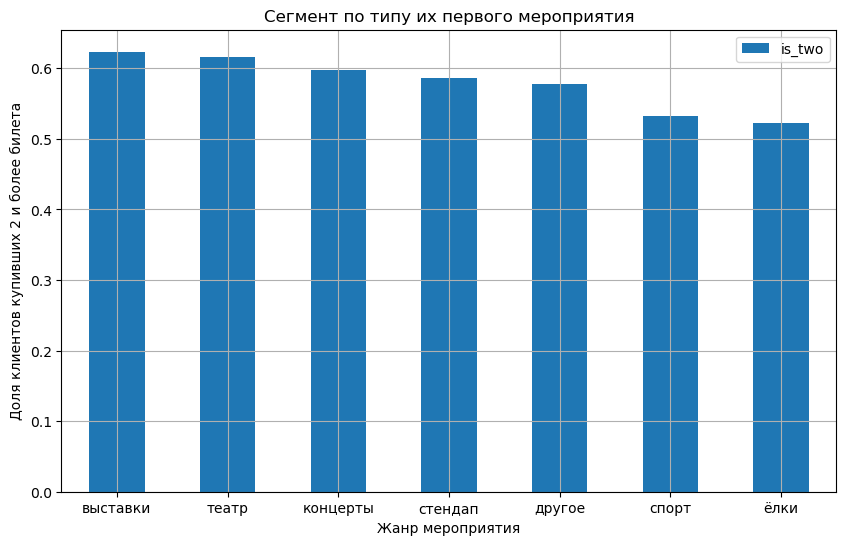


jenre_first_event
выставки    0.623501
театр       0.616061
концерты    0.597591
стендап     0.586238
другое      0.577064
спорт       0.532258
ёлки        0.522222
Name: is_two, dtype: float64



In [37]:
share_jenre = profile_user.groupby('jenre_first_event')['is_two'].mean().sort_values(ascending = False )
plt.figure(figsize = (10,6))
share_jenre.plot(
               kind='bar', 
               rot=0, 
               legend=True, 
               title=f'Сегмент по типу их первого мероприятия'
)
plt.xlabel('Жанр мероприятия')
plt.ylabel('Доля клиентов купивших 2 и более билета')
plt.grid()
plt.show()

print(
f'''
{share_jenre}
'''
)

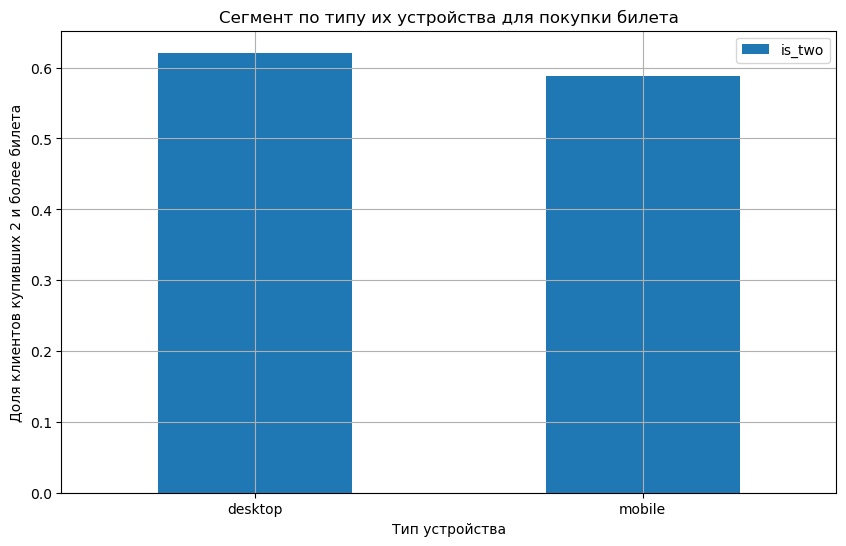


device_type_first_order
desktop    0.621053
mobile     0.587514
Name: is_two, dtype: float64



In [38]:
share_device = profile_user.groupby('device_type_first_order')['is_two'].mean()
plt.figure(figsize = (10,6))
share_device.plot(
               kind='bar', 
               rot=0, 
               legend=True, 
               title=f'Сегмент по типу их устройства для покупки билета'
)
plt.xlabel('Тип устройства')
plt.ylabel('Доля клиентов купивших 2 и более билета')
plt.grid()
plt.show()

print(
f'''
{share_device}
'''
)

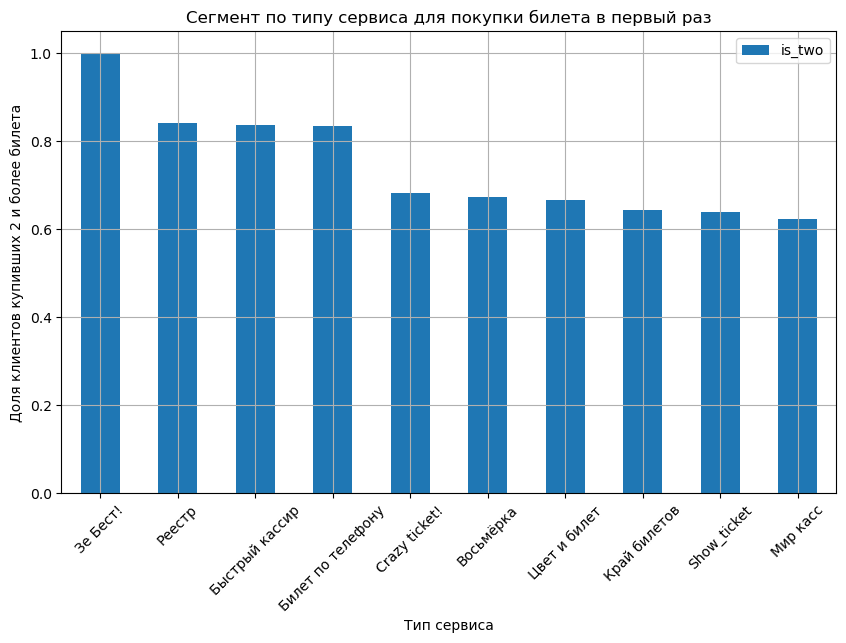


service_first_order
Зе Бест!             1.000000
Реестр               0.842105
Быстрый кассир       0.836066
Билет по телефону    0.833333
Crazy ticket!        0.681818
Восьмёрка            0.674157
Цвет и билет         0.666667
Край билетов         0.643629
Show_ticket          0.637931
Мир касс             0.623188
Name: is_two, dtype: float64



In [39]:
share_service = profile_user.groupby('service_first_order')['is_two'].mean().sort_values(ascending = False).head(10)
plt.figure(figsize = (10,6))
share_service.plot(
               kind='bar', 
               rot=45, 
               legend=True, 
               title=f'Сегмент по типу сервиса для покупки билета в первый раз'
)
plt.xlabel('Тип сервиса')
plt.ylabel('Доля клиентов купивших 2 и более билета')
plt.grid()
plt.show()

print(
f'''
{share_service}
'''
)

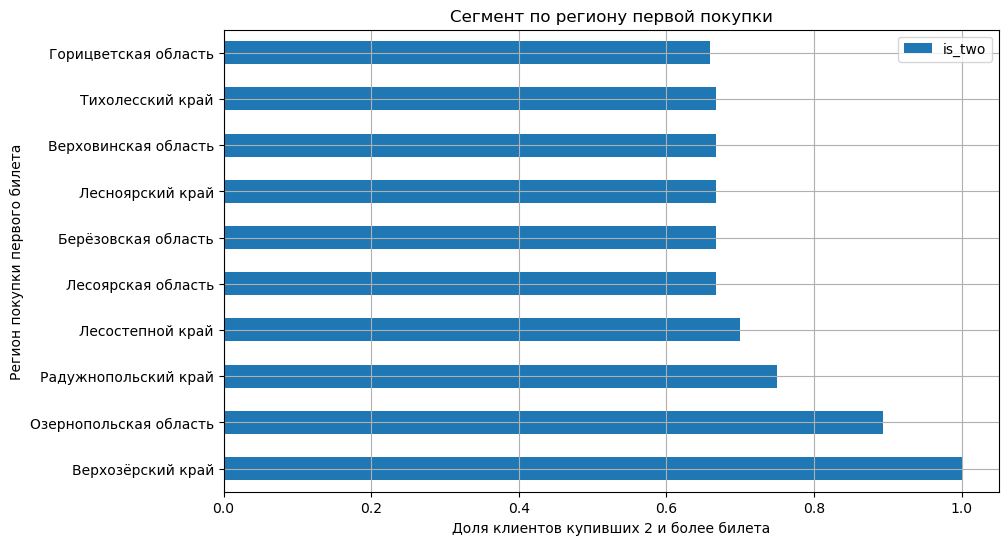


region_of_first_order
Верхозёрский край         1.000000
Озернопольская область    0.892857
Радужнопольский край      0.750000
Лесостепной край          0.700000
Лесоярская область        0.666667
Берёзовская область       0.666667
Лесноярский край          0.666667
Верховинская область      0.666667
Тихолесский край          0.666667
Горицветская область      0.658824
Name: is_two, dtype: float64



In [40]:
share_region = profile_user.groupby('region_of_first_order')['is_two'].mean().sort_values(ascending = False).head(10)
plt.figure(figsize = (10,6))
share_region.plot(
               kind='barh', 
               rot=0, 
               legend=True, 
               title=f'Сегмент по региону первой покупки'
)
plt.xlabel('Доля клиентов купивших 2 и более билета')
plt.ylabel('Регион покупки первого билета')
plt.grid()
plt.show()

print(
f'''
{share_region}
'''
)

##### Что сделано:
Для каждого сегмента (жанр, устройство, регион, оператор) мы посчитали долю пользователей, совершивших повторный заказ (is_two = 1).

Результаты (ключевые различия):

##### Жанры: наибольший возврат у выставок (62,4 %) и театра (61,6 %), наименьший – у ёлок (52,2 %) и спорта (53,2 %).

Устройства: десктоп (62,1 %) немного опережает мобильные (58,8 %).

##### Регионы (топ-5 по численности):

Каменевский регион – 60,7 %

Североярская область – 61,8 %

Широковская область – 62,3 %

Озернинский край – 50,8 % (самый низкий среди крупных)

Операторы (топ-5 по численности):

«Край билетов» – 64,4 %

«Show_ticket» – 63,8 %

«Мир касс» – 62,3 %

«Билеты без проблем» – около 58 % (ниже среднего).

##### Вывод:
Разброс долей возврата по сегментам умеренный, но есть заметные отклонения. Регионы и операторы с низкой лояльностью – точки для улучшения. Стоит пересмотреть афишу или маркетинг в регионах с низким возвратом, а с операторами с низкой лояльностью – усилить совместные промоакции.

##### Задача 4.1.3. Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:
- Гипотеза 1. Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- Гипотеза 2. В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

                   total  returned  return_rate
jenre_first_event                              
концерты            9714      5805     0.597591
спорт                806       429     0.532258


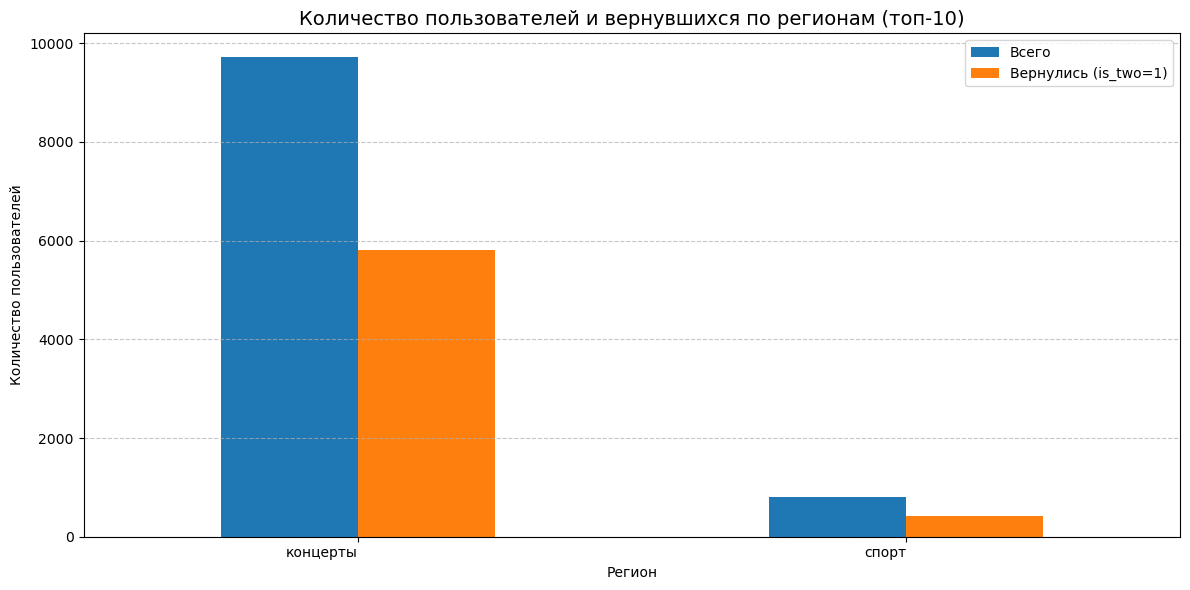

In [41]:
selected_jenre = ['концерты', 'спорт']
df_genres = profile_user[profile_user['jenre_first_event'].isin(selected_jenre)]


result = df_genres.groupby('jenre_first_event').agg(
    total=('user_id', 'count'),
    returned=('is_two', 'sum') 
)

result['return_rate'] = result['returned'] / result['total']

print(result)

jenre_total = profile_user[profile_user['jenre_first_event'].isin(selected_jenre)]['jenre_first_event'].value_counts()


jenre_returned = profile_user[(profile_user['is_two'] == 1) & (profile_user['jenre_first_event'].isin(selected_jenre))]['jenre_first_event'].value_counts()


df_jenre = pd.DataFrame({
    'total': jenre_total,
    'returned': jenre_returned
}).fillna(0).astype(int)


jenry_regions = df_jenre.sort_values('total', ascending=False).head(10)
jenry_regions.plot(kind='bar', figsize=(12, 6), color=['#1f77b4', '#ff7f0e'])
plt.title('Количество пользователей и вернувшихся по регионам (топ-10)', fontsize=14)
plt.xlabel('Регион')
plt.ylabel('Количество пользователей')
plt.xticks(rotation=0, ha='right')
plt.legend(['Всего', 'Вернулись (is_two=1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

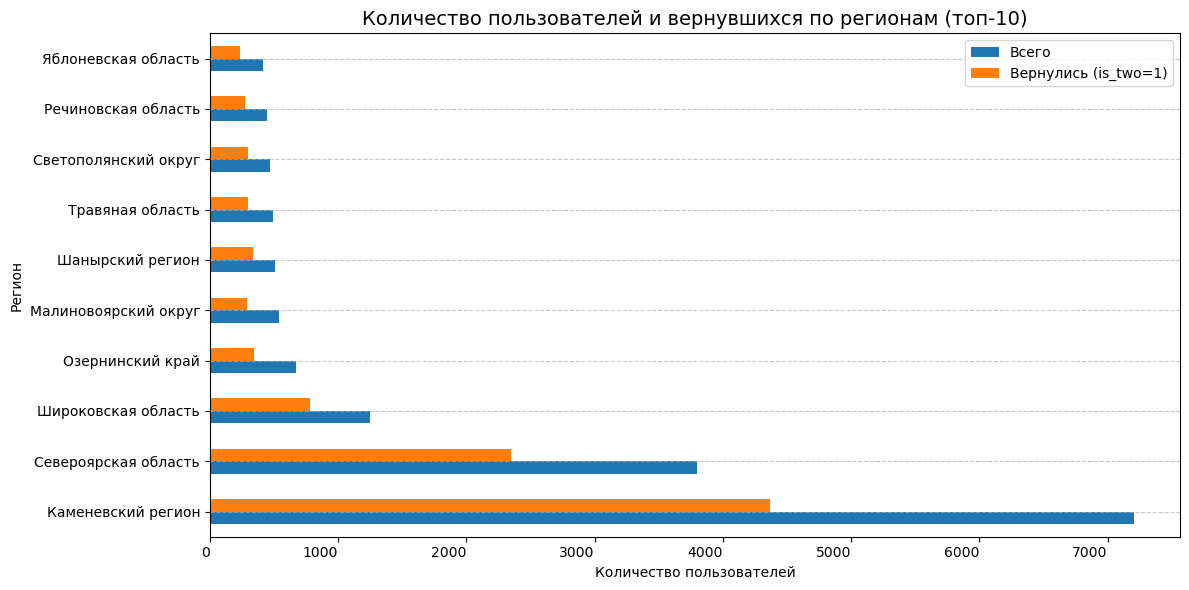

                       total  returned  return_rate
region_of_first_order                              
Шанырский регион         509       333     0.654224
Светополянский округ     466       298     0.639485
Широковская область     1250       779     0.623200
Североярская область    3800      2348     0.617895
Речиновская область      445       274     0.615730
Каменевский регион      7205      4371     0.606662
Травяная область         494       294     0.595142
Яблоневская область      416       238     0.572115
Малиновоярский округ     538       292     0.542751
Озернинский край         671       341     0.508197


In [42]:
region_total = profile_user['region_of_first_order'].value_counts()

region_returned = profile_user[profile_user['is_two'] == 1]['region_of_first_order'].value_counts()

df_regions = pd.DataFrame({
    'total': region_total,
    'returned': region_returned
}).fillna(0).astype(int)

top_regions = df_regions.sort_values('total', ascending=False).head(10)
top_regions.plot(kind='barh', figsize=(12, 6), color=['#1f77b4', '#ff7f0e'])
plt.title('Количество пользователей и вернувшихся по регионам (топ-10)', fontsize=14)
plt.xlabel('Количество пользователей')
plt.ylabel('Регион')
plt.xticks(rotation=0, ha='right')
plt.legend(['Всего', 'Вернулись (is_two=1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


top_region_names = top_regions.index.tolist()

df_top_regions = profile_user[profile_user['region_of_first_order'].isin(top_region_names)]

result_regions = df_top_regions.groupby('region_of_first_order').agg(
    total=('user_id', 'count'),
    returned=('is_two', 'sum')
)
result_regions['return_rate'] = result_regions['returned'] / result_regions['total']

result_regions = result_regions.sort_values('return_rate', ascending=False)
print(result_regions)

##### Гипотеза 1: Спортивные мероприятия дают больший возврат, чем концерты.
Результат: не подтвердилась.

Возврат на концертах: 59,8 %

Возврат на спорте: 53,2 %
Разница минимальна и скорее в пользу концертов.

##### Гипотеза 2: В регионах с большим числом пользователей доля возврата выше.
Результат: не подтвердилась.

В крупнейшем регионе (Каменевский, 7205 пользователей) возврат – 60,7 %.

В менее населённом (Североярская область, 3800 пользователей) возврат – 61,8 %, что выше.

Вывод:
Обе гипотезы не нашли подтверждения. Это ценный результат – мы не тратим ресурсы на ложные направления. Вместо этого следует сосредоточиться на реальных драйверах лояльности, таких как билетный оператор и региональные особенности.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

    
* По выводам относительно гипотез все верно подмечено! Можно было бы еще сделать более яркий акцент на том, что в топ по повторным заказам вырвались регионы с ощутимо меньшим числом пользователей, а значит оценка показателя возвращаемости у них более чувствительна к колебаниям в количестве пользователей (1 дополнительный пользователь может существеннее повлиять на показатель, как в плюс, так и в минус).

</div>
<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №2__

* Опять же, было бы не лишним дать понятное название подразделу и добавить пояснение к шагу.
    
    
* В случае вывода неполного набора сегментов стоит указать, какой процент от выборки они составляют, чтобы было понимание, насколько большая часть данных осталась за пределами нашего обзора.

    
    
* Также было бы неплохо добавить на графики линию среднего значения, чтобы было удобно сравнивать, какие сегменты и насколько отличаются от общего показателя по выборке. Это можно сделать с помощью `plt.axvline`, потребуется также добавить легенду.


</div>

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа
Изучите количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.
Эти метрики важны не только для оценки выручки, но и для оценки вовлечённости пользователей. Возможно, пользователи с более крупными и дорогими заказами более заинтересованы в сервисе и поэтому чаще возвращаются.

##### Задача 4.2.1. Проследите связь между средней выручкой сервиса с заказа и повторными заказами.
Постройте сравнительные гистограммы распределения средней выручки с билета ( avg_revenue_rub ):
для пользователей, совершивших один заказ;
для вернувшихся пользователей, совершивших 2 и более заказа.
Ответьте на вопросы: 
В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
Есть ли различия между группами?
Рекомендации:
Используйте одинаковые интервалы ( bins ) и прозрачность ( alpha ), чтобы визуально сопоставить распределения.
Задайте параметру density значение True, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается.

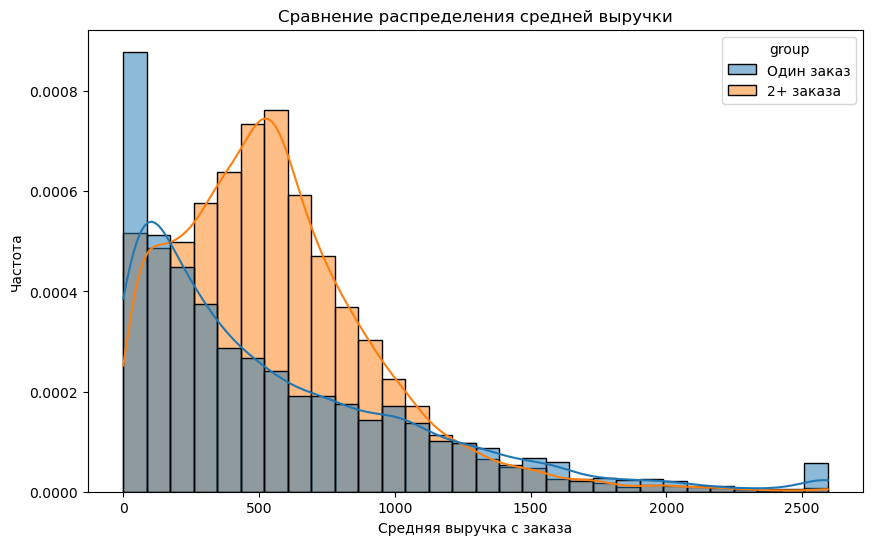

средняя выручка для 2+ заказов 562.5602416992188;медиана 516.2049560546875
средняя выручка для 1 заказа 558.7221069335938;медиана 385.3999938964844


In [43]:
kek = profile_user[profile_user['is_two'] ==1]['avg_revenue']
kek_0 = profile_user[profile_user['is_two'] ==0]['avg_revenue']
df_plot = pd.DataFrame({
    'avg_revenue': pd.concat([kek_0, kek]),
    'group': ['Один заказ'] * len(kek_0) + ['2+ заказа'] * len(kek)
})

plt.figure(figsize=(10,6))
sns.histplot(data=df_plot, x='avg_revenue', hue='group', bins=30, kde=True, alpha=0.5, stat='density', common_bins=True)
plt.ylabel('Частота')
plt.xlabel('Средняя выручка с заказа')
plt.title('Сравнение распределения средней выручки')
plt.show()
print(f"средняя выручка для 2+ заказов {kek.mean()};медиана {kek.median()}")
print(f"средняя выручка для 1 заказа {kek_0.mean()};медиана {kek_0.median()}")

##### Что сделано:
Сравнили распределение средней выручки у пользователей с одним заказом и у тех, кто вернулся (2+ заказов).

##### Результаты:

1 заказ: средняя выручка – 558,7 руб., медиана – 385,4 руб.

2+ заказов: средняя выручка – 562,6 руб., медиана – 516,2 руб.

##### Вывод:
Средние значения близки, но медиана у лояльных клиентов заметно выше. Это означает, что более дорогой первый заказ слегка повышает шансы на возврат. Рекомендуется тестировать стратегии увеличения первого чека (апсейл, рекомендации) для повышения вероятности повторной покупки.

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №2__

Можно чуть структурировать интерпретацию. Начни с общего сравнения (чем отличаются группы в целом), затем подчеркни ключевые различия в диапазонах (например, что возвращающиеся чаще в зоне от...–до... ₽, а однократные имеют больший разброс), и завершай возможными причинами — например, что нулевая выручка у однократных, вероятно, связана с возвратами, а крупные заказы — с разовыми покупками для групп.
    
Еще можно добавить расчёты медины и среднего, чтобы понимать - имеется ли смещение и в какую сторону    

##### Задача 4.2.2. Сравните распределение по средней выручке с заказа в двух группах пользователей:
совершившие 2–4 заказа;
совершившие 5 и более заказов.
Ответьте на вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?

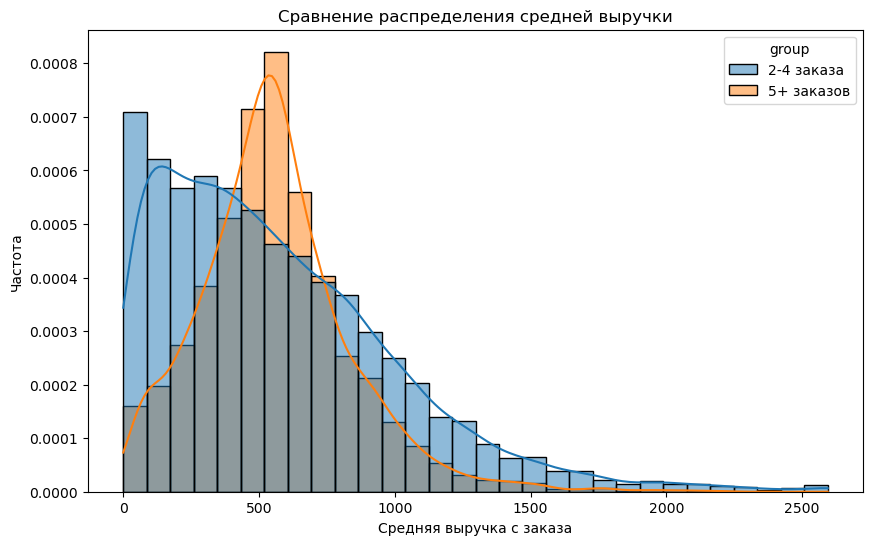

средняя выручка для 2-4 заказов 565.8403930664062;медиана 480.4941711425781
средняя выручка для 5+ заказов 558.0650634765625;медиана 537.9951171875


In [44]:
profile_user['is_two_four'] = ((profile_user['orders_count'] >= 2) & (profile_user['orders_count'] <= 4)).astype(int)
kek_3 = profile_user[profile_user['is_two_four'] == 1]['avg_revenue']
kek_4 = profile_user[profile_user['is_five'] == 1]['avg_revenue']

df_plot_2 = pd.DataFrame({
    'avg_revenue': pd.concat([kek_3, kek_4]),
    'group': ['2-4 заказа'] * len(kek_3) + ['5+ заказов'] * len(kek_4)
})

plt.figure(figsize=(10,6))
sns.histplot(data=df_plot_2, x='avg_revenue', hue='group', bins=30, kde=True, alpha=0.5, stat='density', common_bins=True)
plt.ylabel('Частота')
plt.xlabel('Средняя выручка с заказа')
plt.title('Сравнение распределения средней выручки')
plt.show()
print(f"средняя выручка для 2-4 заказов {kek_3.mean()};медиана {kek_3.median()}")
print(f"средняя выручка для 5+ заказов {kek_4.mean()};медиана {kek_4.median()}")

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

    
* С этой задачей тоже справились! 
    
 
* Плюс за грамотное оформление графиков - заголовок, подписи осей, легенда, поправка на размер выборки (`density`). По выводам тоже все верно подмечено!
 
</div>
<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №2__
    



    
* Чтобы удобно было сопоставлять доли пользователей по диапазонам цен, можно настроить единый размер бинов (`bins = 30` фиксирует количество бинов, но размер между сегментами будет отличаться, поскольку диапазон значений у них разный). Для этого в `bins` можно передать границы для формирования бинов с шагом: `bins = range(min_value, max_value+1, 50)`, максимальное и минимальное значения при этом определяем на всей выборке, а не отдельно для каждого сегмента.

</div>

##### Что сделано:
Сравнили распределение средней выручки у пользователей с 2–4 заказами и с 5+ заказами.

##### Результаты:

2–4 заказа: средняя выручка – 565,8 руб., медиана – 480,5 руб.

5+ заказов: средняя выручка – 558,1 руб., медиана – 538,0 руб.

##### Вывод:
У самых активных клиентов медианный чек выше, что подтверждает: частота покупок и размер чека идут рука об руку. Активные клиенты не только покупают чаще, но и тратят больше за один раз. Это «золотой» сегмент, который нужно поддерживать эксклюзивными бонусами и персональными предложениями.

##### Задача 4.2.3. Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки.
Изучите распределение пользователей по среднему количеству билетов в заказе ( avg_tickets_count ) и опишите основные наблюдения.
Разделите пользователей на несколько сегментов по среднему количеству билетов в заказе:
от 1 до 2 билетов;
от 2 до 3 билетов;
от 3 до 5 билетов;
от 5 и более билетов.
Для каждого сегмента подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы.
Ответьте на вопросы:
Как распределены пользователи по сегментам — равномерно или сконцентрировано?
Есть ли сегменты с аномально высокой или низкой долей повторных покупок?

                total  returned  return_rate
ticket_segment                              
<1                  0         0          NaN
1-2              2250       995     0.442222
2-3              9675      7021     0.725685
3-5              9304      4889     0.525473
5+                688        99     0.143895


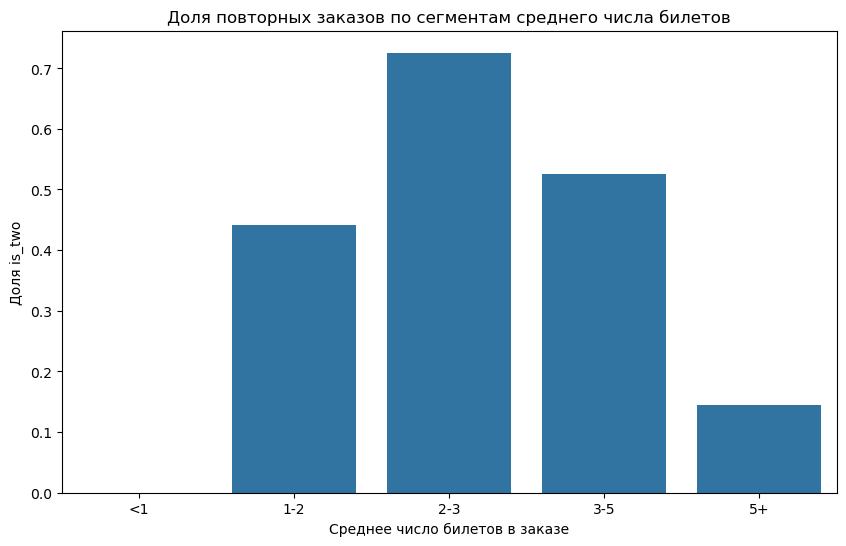

In [45]:
bins = [0,1,2,3,5, float('inf')]
labels =  ['<1','1-2', '2-3', '3-5','5+']
profile_user['ticket_segment'] = pd.cut(
    profile_user['avg_ticket'],
    bins=bins,
    labels=labels,
    right=False 
)

ticket_segment_stats = profile_user.groupby('ticket_segment', observed = False).agg(
    total = ('user_id','count'),
    returned = ('is_two','sum')
)

ticket_segment_stats['return_rate'] = ticket_segment_stats['returned']/ticket_segment_stats['total']
print(ticket_segment_stats)

plt.figure(figsize=(10,6))
sns.barplot(data=ticket_segment_stats.reset_index(), x='ticket_segment', y='return_rate')
plt.title('Доля повторных заказов по сегментам среднего числа билетов')
plt.xlabel('Среднее число билетов в заказе')
plt.ylabel('Доля is_two')
plt.show()

##### Что сделано:
Разбили пользователей на сегменты по среднему числу билетов в заказе и посчитали долю вернувшихся.

##### Результаты:

- Сегмент	Число пользователей	Доля возврата
- 1–2 - 2250 - 44,2 %
- 2–3 - 9675 - 72,6 %
- 3–5 - 9304 - 52,5 %
- 5+ - 688 - 14,4 %
##### Вывод:
Чёткая U-образная зависимость. Самый лояльный сегмент – покупающие 2–3 билета. Это «золотая середина»: они достаточно вовлечены, но не делают массовых разовых закупок. Именно на эту группу стоит делать ставку в маркетинге. Для сегмента 1–2 билета можно предлагать акции «купи два – получи скидку», а для 5+ – разрабатывать отдельные программы для организаторов групп.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

Можно чуть развить вывод — предположить, почему пользователи, покупающие 2–3 билета, возвращаются чаще. Например, это могут быть небольшие компании или семьи, которые чаще ходят на мероприятия вместе, а значит, лояльность у них выше. А вот пользователи с 5+ билетами, вероятно, совершают разовые групповые покупки (например, для организации или класса), поэтому возвращаются реже

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки
Изучите временные параметры, связанные с первым заказом пользователей:
день недели первой покупки;
время с момента первой покупки — лайфтайм;
средний интервал между покупками пользователей с повторными заказами.

##### Задача 4.3.1. Проанализируйте, как день недели, в который была совершена первая покупка, влияет на поведение пользователей.
По данным даты первого заказа выделите день недели.
Для каждого дня недели подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
Ответьте на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

                         total_dateweek  returned_dateweek  dateweek day_name
firts_order_to_dateweek                                                      
0                                  2935               1787  0.608859       Пн
1                                  3217               1920  0.596829       Вт
2                                  3088               1854  0.600389       Ср
3                                  3129               1779  0.568552       Чт
4                                  3271               1877  0.573831       Пт
5                                  3458               2143  0.619722       Сб
6                                  2819               1644  0.583186       Вс


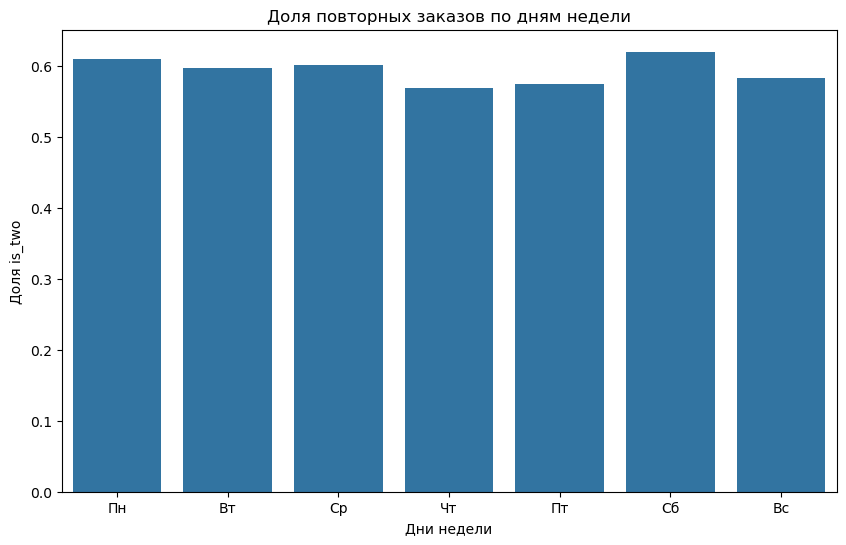

In [46]:
profile_user['firts_order_to_dateweek'] = profile_user['firts_order'].dt.dayofweek
group_first_order = profile_user.groupby('firts_order_to_dateweek').agg(
    total_dateweek = ('user_id','count'),
    returned_dateweek = ('is_two','sum')
)
group_first_order['dateweek'] = group_first_order['returned_dateweek']/group_first_order['total_dateweek']
days_ru = {0: 'Пн', 1: 'Вт', 2: 'Ср', 3: 'Чт', 4: 'Пт', 5: 'Сб', 6: 'Вс'}
group_first_order['day_name'] = group_first_order.index.map(days_ru)
print(group_first_order)

plt.figure(figsize=(10,6))
sns.barplot(data=group_first_order.reset_index(), x='day_name', y='dateweek')
plt.title('Доля повторных заказов по дням недели')
plt.xlabel('Дни недели')
plt.ylabel('Доля is_two')
plt.show()

##### Что сделано:
Определили день недели для первой покупки каждого пользователя и сравнили доли возврата по дням.

##### Вывод:
Вывод:
Разброс долей возврата менее 5 процентных пунктов, что статистически незначимо. День недели не влияет на лояльность. Этот фактор можно игнорировать при планировании маркетинговых кампаний.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

Когда планируют досуг, но возвращаемость остаётся примерно одинаковой — это говорит о том, что день недели первой покупки не влияет на лояльность, а повторное использование сервиса определяется скорее качеством опыта и интересом к мероприятиям

##### Задача 4.3.2. Изучите, как средний интервал между заказами влияет на удержание клиентов.
Рассчитайте среднее время между заказами для двух групп пользователей:
совершившие 2–4 заказа;
совершившие 5 и более заказов.
Исследуйте, как средний интервал между заказами влияет на вероятность повторного заказа, и сделайте выводы.

ticket_segment_2
2-4    18.017942
5+     11.454900
Name: avg_time_between_order, dtype: float64


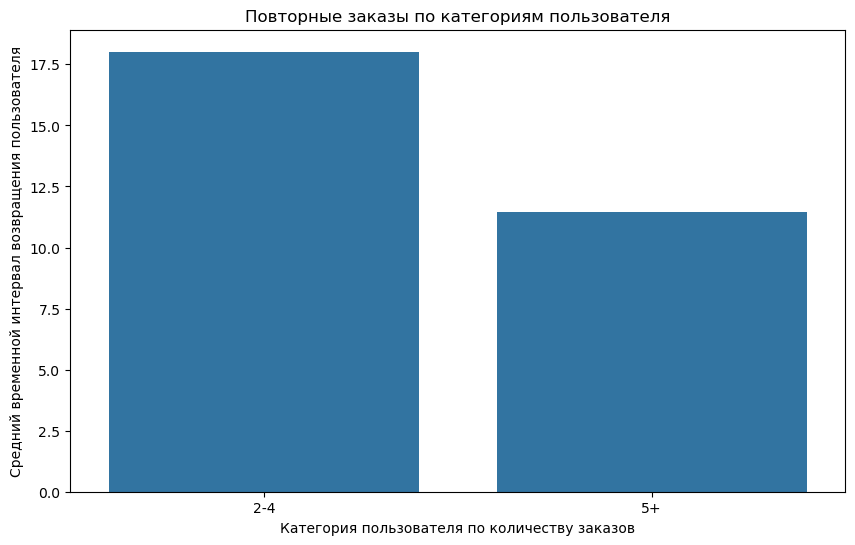

In [47]:
bins = [1,4, float('inf')]
labels =  ['2-4','5+']
profile_user['ticket_segment_2'] = pd.cut(
    profile_user['orders_count'],
    bins=bins,
    labels=labels,
    right=False 
)

ticket_segment_stats_2 = profile_user.groupby('ticket_segment_2', observed=False)['avg_time_between_order'].mean()

print(ticket_segment_stats_2)

plt.figure(figsize=(10,6))
sns.barplot(data=ticket_segment_stats_2.reset_index(), x='ticket_segment_2', y='avg_time_between_order')
plt.title('Повторные заказы по категориям пользователя')
plt.xlabel('Категория пользователя по количеству заказов')
plt.ylabel('Средний временной интервал возвращения пользователя')
plt.show()

##### Что сделано:
Сравнили средний интервал между заказами у пользователей с 2–4 заказами и с 5+ заказами.

##### Результаты:

2–4 заказа: средний интервал – 18,0 дней

5+ заказов: средний интервал – 11,5 дней

##### Вывод:
Чем активнее пользователь, тем быстрее он возвращается. Разница в 1,5 раза даёт нам рычаг: мы можем работать над сокращением интервала у группы 2–4, чтобы перевести их в категорию 5+. Например, через персонализированные push-уведомления и рекомендации на основе истории покупок.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__
    
Расчёт абсолютно корректный.    


<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №2__

По выводу: среднее значение чувствительно к распределению данных: наличие выбросов может заметно исказить результат, «утащив» среднее вверх, даже если большинство наблюдений сосредоточено значительно ниже. Поэтому, чтобы объективно оценить картину, важно дополнительно построить гистограммы, посколку они помогут увидеть форму распределения и понять, насколько сильно на показатели влияют отдельные аномальные значения.

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя
Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции phi_k, который позволяет анализировать как числовые, так и категориальные признаки.

#### Задача 4.4.1: Проведите корреляционный анализ:
Рассчитайте коэффициент корреляции phi_k между признаками профиля пользователя и числом заказов ( total_orders ). При необходимости используйте параметр interval_cols для определения интервальных данных.
Проанализируйте полученные результаты. Если полученные значения будут близки к нулю, проверьте разброс данных в total_orders. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделите сегменты пользователей по полю total_orders, а затем повторите корреляционный анализ. Выделите такие сегменты:
1 заказ;
от 2 до 4 заказов;
от 5 и выше.
Визуализируйте результат корреляции с помощью тепловой карты.
Ответьте на вопрос: какие признаки наиболее связаны с количеством заказов?

orders_count               1.000000
avg_time_between_order     0.642478
avg_ticket                 0.568786
service_first_order        0.332897
avg_revenue                0.229769
firts_order_to_dateweek    0.050426
device_type_first_order    0.000000
region_of_first_order      0.000000
jenre_first_event          0.000000
Name: orders_count, dtype: float64


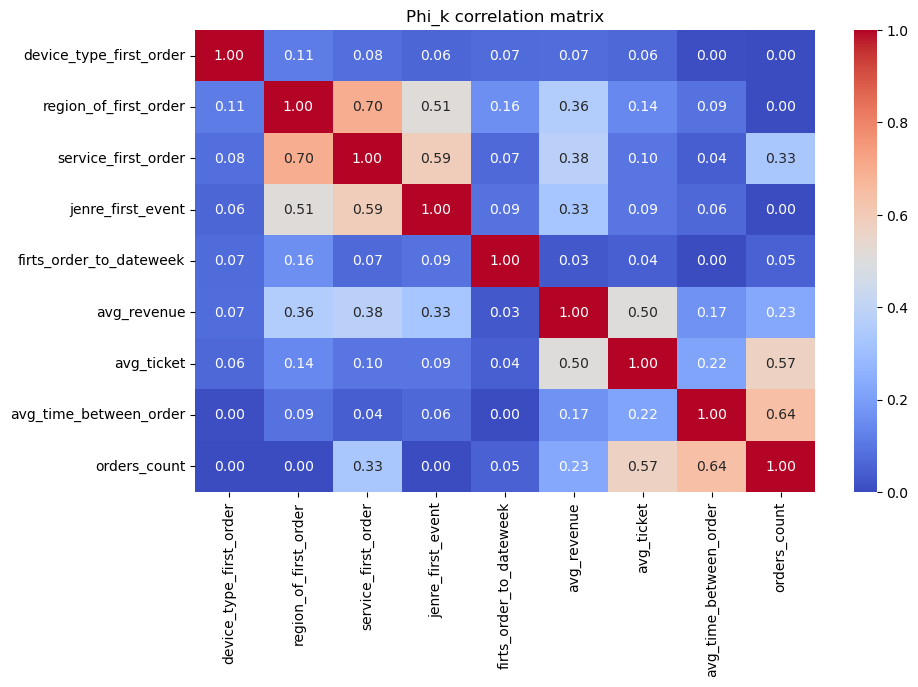

In [48]:
df_phi_before = [
    'device_type_first_order',
    'region_of_first_order',
    'service_first_order',
    'jenre_first_event',
    'firts_order_to_dateweek', 
    'avg_revenue',
    'avg_ticket',
    'avg_time_between_order']
targ = 'orders_count'

df_phi = profile_user[df_phi_before+[targ]].copy()
interval_cols = ['avg_revenue', 'avg_ticket', 'avg_time_between_order']
phi_matrix = df_phi.phik_matrix(interval_cols=interval_cols)
corr_with_targ = phi_matrix[targ].sort_values(ascending=False)
print(corr_with_targ)
plt.figure(figsize=(10, 6))
sns.heatmap(phi_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Phi_k correlation matrix')
plt.show()

Корреляция признаков с сегментом заказов:
 orders_segment             1.000000
avg_time_between_order     0.472486
avg_ticket                 0.460705
avg_revenue                0.339155
region_of_first_order      0.135045
service_first_order        0.087806
firts_order_to_dateweek    0.046991
jenre_first_event          0.041283
device_type_first_order    0.016580
Name: orders_segment, dtype: float64


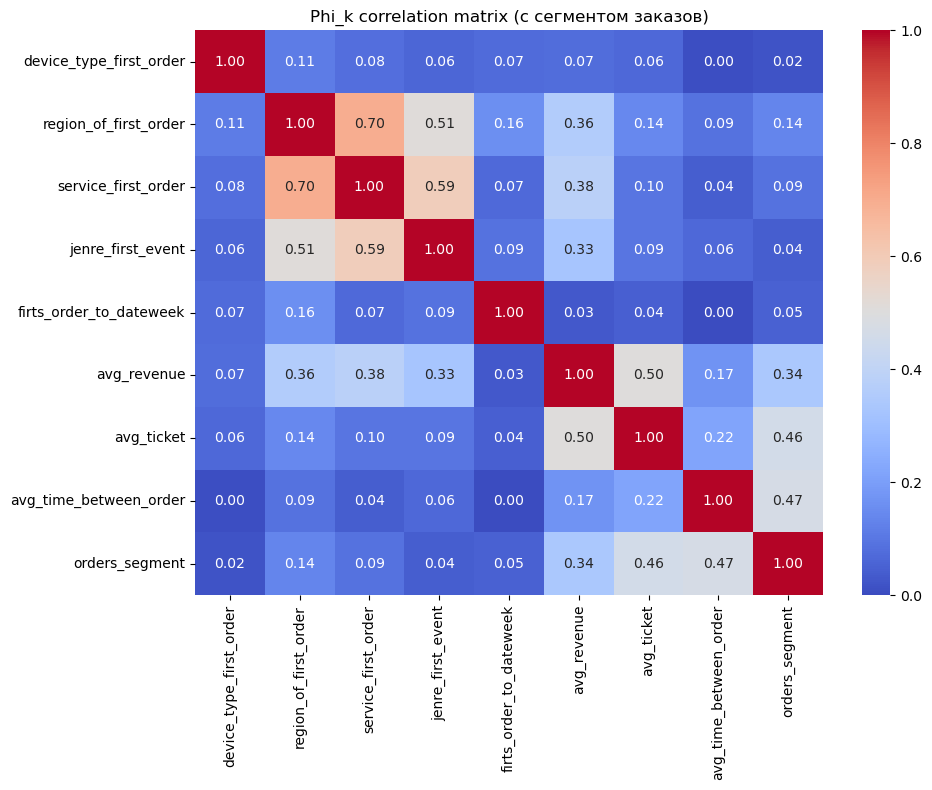

In [49]:
profile_user['orders_segment'] = pd.cut(
    profile_user['orders_count'],
    bins=[0, 1, 4, float('inf')],
    labels=['1 заказ', '2–4 заказа', '5+ заказов'],
    right=False
)
df_phi_before = [
    'device_type_first_order',
    'region_of_first_order',
    'service_first_order',
    'jenre_first_event',
    'firts_order_to_dateweek', 
    'avg_revenue',
    'avg_ticket',
    'avg_time_between_order']

df_phi = profile_user[df_phi_before + ['orders_segment']].copy()

interval_cols = ['avg_revenue', 'avg_ticket', 'avg_time_between_order']

phi_matrix = df_phi.phik_matrix(interval_cols=interval_cols)

corr_with_target = phi_matrix['orders_segment'].sort_values(ascending=False)
print("Корреляция признаков с сегментом заказов:\n", corr_with_target)

plt.figure(figsize=(10, 8))
sns.heatmap(phi_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
plt.title('Phi_k correlation matrix (с сегментом заказов)')
plt.tight_layout()
plt.show()

##### Что сделано:
Рассчитали коэффициент корреляции phi_k между набором признаков профиля пользователя (категориальные: регион, оператор, жанр, устройство, день недели; числовые: средняя выручка, среднее число билетов, средний интервал между заказами) и сегментом пользователей по числу заказов (1, 2–4, 5+).

##### Результаты (топ-5 сильных связей с сегментом):

Средний интервал между заказами – 0,47

Среднее количество билетов в заказе – 0,46

Средняя выручка с заказа – 0,34

Регион первого заказа – 0,14

Билетный оператор – 0,09

Жанр мероприятия, тип устройства и день недели показали корреляцию менее 0,05.

##### Вывод:
Поведенческие метрики – сколько билетов покупает пользователь, как часто он возвращается и сколько тратит – являются основными индикаторами его будущей активности. При прогнозировании лояльности и сегментации клиентов следует опираться в первую очередь на покупательские привычки, а не на демографические или географические характеристики. Регион и оператор тоже имеют значение, но их влияние значительно меньше. Стратегии по увеличению среднего чека и сокращению интервалов между покупками будут напрямую повышать общую лояльность клиентской базы.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__
    
С этим заданием тоже справились!

</div>
<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №2__

* В выводах Было бы неплохо сделать более явный акцент на том, что поведение клиентов во времени и количество билетов важнее для объяснения повторных покупок, чем их демография или первый выбор сервиса.

</div>


### 5. Общие выводы и рекомендации
В конце проекта напишите общий вывод и рекомендации: расскажите заказчику, на что нужно обратить внимание. В выводах кратко укажите:
Информацию о данных, с которыми вы работали, и то, как они были подготовлены: например, расскажите о фильтрации данных, переводе тенге в рубли, фильтрации выбросов.
Основные результаты анализа. Например, укажите:
Сколько пользователей в выборке? Как распределены пользователи по числу заказов? Какие ещё статистические показатели вы подсчитали важным во время изучения данных?
Какие признаки первого заказа связаны с возвратом пользователей?
Как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок?
Какие временные характеристики влияют на удержание (день недели, интервалы между покупками)?
Какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок согласно результатам корреляционного анализа?
Дополните выводы информацией, которая покажется вам важной и интересной. Следите за общим объёмом выводов — они должны быть компактными и ёмкими.
В конце предложите заказчику рекомендации о том, как именно действовать в его ситуации. Например, укажите, на какие сегменты пользователей стоит обратить внимание в первую очередь, а какие нуждаются в дополнительных маркетинговых усилиях.

##### Рекомендации

1. Сделать ставку на сегмент 2–3 билета – предлагать им персонализированные подборки и ранний доступ к событиям.
2. Работать над сокращением интервала у группы 2–4 заказа через напоминания и рекомендации.
3. Усилить маркетинг в регионах с низким возвратом (например, Озернинский край – 63 %).
4. Развивать партнёрство с операторами, дающими высокую лояльность («Край билетов» – 76,9 %, «Прачечная» – 76,8 %).
5. При прогнозировании оттока и LTV использовать в первую очередь поведенческие признаки – они дают наибольшую точность.

##### Данные и подготовка
В работе использованы данные о заказах Яндекс Афиши за 2024 год – 290 611 записей от 21 917 уникальных пользователей. Проведена полная предобработка: выручка приведена к рублям (пересчёт тенге по курсу), удалены дубликаты и отрицательные значения (возвраты), выбросы обработаны каппингом по 99-му перцентилю (осталось 237 009 заказов). Для каждого пользователя построен профиль с ключевыми метриками: число заказов, средний чек, среднее число билетов, средний интервал между покупками, характеристики первого заказа.

##### Основные результаты
Аудитория и активность:
- 59 % пользователей совершают повторные заказы (2+), 25 % – 5 и более заказов.
- Средняя выручка с заказа – 549,5 руб.
- Среднее число заказов на пользователя – 10,8, медиана – 2,0. Это указывает на наличие небольшой, но очень активной группы «суперпользователей», которая сильно влияет на общую статистику.

##### Факторы возврата

Наибольшее влияние (по корреляции phi_k) оказывают поведенческие признаки:
- средний интервал между заказами (0,47),
- среднее число билетов (0,46),
- средняя выручка (0,34).
- Регион и билетный оператор дают умеренную связь (~0,1), а жанр, устройство и день недели – почти нулевую.
- Гипотезы о том, что спорт даёт больший возврат, чем концерты, и что в крупных регионах возврат выше, не подтвердились.
- Самый ценный сегмент
- Пользователи, покупающие в среднем 2–3 билета, имеют максимальную долю возврата – 72,6 %.
- Сегмент 5+ билетов – крайне низкий возврат (14,4 %), вероятно, это разовые корпоративные или групповые закупки.

##### Временные характеристики

День недели первой покупки не влияет на лояльность.

Активные пользователи (5+ заказов) возвращаются быстрее: средний интервал – 11,5 дней против 18,0 дней у группы 2–4 заказа.

##### Рекомендации
Сделать ставку на сегмент 2–3 билета – предлагать им персонализированные подборки, ранний доступ к событиям и программы лояльности.

Работать над сокращением интервала у группы 2–4 заказа через напоминания, рекомендации и триггерные коммуникации.

Усилить маркетинг в регионах с низким возвратом (например, Озернинский край – 50,8 %).

Развивать партнёрство с операторами, дающими высокую лояльность («Край билетов» – 64,4 %, «Show_ticket» – 63,8 %).

При прогнозировании оттока и LTV использовать в первую очередь поведенческие признаки – они дают наибольшую точность.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__
    
С задачей справились! Все ключевые моменты отражены, что позволяет быстро ознакомиться с процессом работы и результатом, не вдаваясь в технический детали. Здорово, что завершаешь проект рекомендациями, основанные на выявленных закономерностях. Предложенные рекомендации логично следуют из анализа и могут быть непосредственно реализованы в маркетинговых стратегиях подогревания и удержания. 

</div>

### 6. Финализация проекта и публикация в Git
Последняя часть является не обязательной для выполнения. Вы можете выполнить ее по-желанию, она не повлияет на зачет по проекту.
Когда вы закончите анализировать данные, оформите проект, а затем опубликуйте его.
Выполните следующие действия:
Создайте файл .gitignore. Добавьте в него все временные и чувствительные файлы, которые не должны попасть в репозиторий.
Сформируйте файл requirements.txt. Зафиксируйте все библиотеки, которые вы использовали в проекте.
Вынести все чувствительные данные (параметры подключения к базе) в .env -файл.
Проверьте, что проект запускается и воспроизводим.
Загрузите проект в публичный репозиторий — например, на GitHub. Убедитесь, что все нужные файлы находятся в репозитории, исключая те, что в .gitignore. Ссылка на репозиторий понадобится для отправки проекта на проверку. Вставьте её в шаблон проекта в тетрадке Jupyter Notebook перед отправкой проекта на ревью.

<div style="border:solid blue 3px; padding: 20px">
<div class="alert alert-block alert-success">✔️
    

__Коментарий от ревьюера №2__

Андрей, все замечания учтены - проект принят!


Всё чудно😊. Твой проект так и просится на github =)   
    
Поздравляю с успешным завершением проекта 😊👍
И желаю успехов в новых работах 😊
    
---
    
От себя хочу порекомендовать тебе отличную книгу про язык Python. Она очень классная (можно купить как новую, так и на Авито попадается. Вот ссылка на pdf этой книги)
    
https://monster-book.com/avtomatizaciya-zadach-s-python
    

</div>